# L3.4 · Churn classification and the call list

**Day 3 slides** 21 and the churn part of 23

### The problem

A team has time to call only some customers. Can we use information we already have to guess who might leave and decide whom to call?

### What we’re doing

Use the label left or stayed to compare four classifiers. Use the chosen model’s chance of leaving to build a call list and check it on a fresh group of customers.

### Why we’re doing it

A score tells us how strongly the model expects a customer to leave. The budget and value of a successful call help us decide how far down the list to go.

Read the text above a code cell, then click the cell and press
**Shift + Enter**. Run from the top. The files contain synthetic course data.

## Setup · Open the data

Use four clues from the customer snapshot. A recorded closure or retention offer can give away the answer, so neither is loaded. Split distinct customers into train, validation and test with similar shares of recorded churn. Run this cell as written. The import lines make the tools
available. The folder lines find the supplied data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

from pathlib import Path

here = Path.cwd()
data = next((folder / "data" for folder in (here, *here.parents)
             if (folder / "data" / "loan_applications.csv").is_file()), None)
if data is None:
    raise FileNotFoundError("Open the extracted course folder in Jupyter or VS Code.")

inputs = ["digital_logins_30d", "branch_visits_90d", "days_since_last_txn", "num_products"]
columns = ["customer_id", "churned_6m"] + inputs
customers = pd.read_csv(data / "customers_raw.csv", usecols=columns)
customers = customers.drop_duplicates("customer_id").dropna()
customers = customers[(customers[inputs] >= 0).all(axis=1)].sample(10000, random_state=42)
train, remaining = train_test_split(customers, test_size=.4, random_state=42,
                                    stratify=customers["churned_6m"])
valid, test = train_test_split(remaining, test_size=.5, random_state=42,
                              stratify=remaining["churned_6m"])
display(train[inputs + ["churned_6m"]].head(3))

,digital_logins_30d,branch_visits_90d,days_since_last_txn,num_products,churned_6m
25844,16.0,0,2,3,0
225540,15.0,0,4,2,0
105360,22.0,0,1,4,0


## 1 · Compare four models on one check group

**What we’re doing.** Train a logistic model, KNN, a small tree and a forest. Compare how well their scores bring churners toward the top on the same validation customers.

**Why.** The methods make different kinds of guesses. Using the same inputs, training rows and check rows makes the comparison easier to interpret.

**Look for.** The table uses average precision, which rewards putting actual churners toward the top. That matters when we can only call the first part of the list.

In [2]:
models = {
    "Logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25)),
    "Tree": DecisionTreeClassifier(max_depth=3, min_samples_leaf=30, random_state=42),
    "Forest": RandomForestClassifier(n_estimators=24, max_depth=6, min_samples_leaf=20, random_state=42),
}
scores = {}
for name, model in models.items():
    model.fit(train[inputs], train["churned_6m"])
    predicted = model.predict_proba(valid[inputs])[:, 1]
    scores[name] = average_precision_score(valid["churned_6m"], predicted)
display(pd.Series(scores, name="Validation average precision").sort_values(ascending=False).round(3))

Logistic    0.161
Forest      0.158
Tree        0.146
KNN         0.143
Name: Validation average precision, dtype: float64

## 2 · See what happens when a tree asks more questions

**What we’re doing.** Fit trees that can ask up to two, four or ten levels of questions. Show training and validation scores.

**Why.** A large tree can remember details of its training rows. An improving training score is only useful if a later check improves too.

**Look for.** The gap between training and validation helps diagnose overfitting.

In [3]:
rows = []
for depth in [2, 4, 10]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(train[inputs], train["churned_6m"])
    learns = average_precision_score(train["churned_6m"], tree.predict_proba(train[inputs])[:, 1])
    checks = average_precision_score(valid["churned_6m"], tree.predict_proba(valid[inputs])[:, 1])
    rows.append([depth, learns, checks])
display(pd.DataFrame(rows, columns=["Depth", "Train score", "Validation score"]).round(3))

,Depth,Train score,Validation score
0,2,0.151,0.142
1,4,0.170,0.147
2,10,0.330,0.138


## 3 · Turn an ordered list into groups of ten percent

**What we’re doing.** Pick the best model from step 1. Sort validation customers by its score, form ten groups and compare their recorded churn rates.

**Why.** The team starts at the top. Lift asks how much more often people leave in a group than in the overall validation set.

**Look for.** Group one has the highest scores. A lift of two means its churn rate is twice the overall rate.

In [4]:
chosen = max(scores, key=scores.get)
model = models[chosen]
ranked = valid.copy()
ranked["score"] = model.predict_proba(valid[inputs])[:, 1]
ranked = ranked.sort_values("score", ascending=False).reset_index(drop=True)
ranked["band"] = ranked.index * 10 // len(ranked) + 1
bands = ranked.groupby("band")["churned_6m"].agg(customers="size", churners="sum", rate="mean")
bands["lift"] = bands["rate"] / ranked["churned_6m"].mean()
display(bands.round(3))

,customers,churners,rate,lift
band,,,,
1,200,35,0.175,1.477
2,200,33,0.165,1.392
3,200,38,0.190,1.603
4,200,25,0.125,1.055
5,200,27,0.135,1.139
6,200,16,0.080,0.675
7,200,23,0.115,0.970
8,200,17,0.085,0.717
9,200,14,0.070,0.591


## 4 · Draw how many churners the call list reaches

**What we’re doing.** Walk down the score list and plot the share of customers contacted against the share of recorded churners included.

**Why.** This gains chart answers a budget question. At a given share contacted, it shows how many of the people who actually left appear on the list.

**Look for.** The dashed line represents reaching the same share of churners as the share contacted. Read the model’s curve at a budget such as 10%.

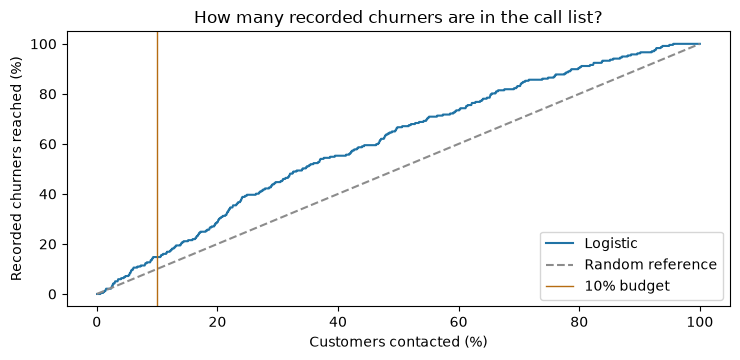

In [5]:
contacted = np.arange(1, len(ranked) + 1) / len(ranked) * 100
reached = ranked["churned_6m"].cumsum() / ranked["churned_6m"].sum() * 100
fig, ax = plt.subplots(figsize=(7.5, 3.7))
ax.plot(contacted, reached, label=chosen, color="#2073a5")
ax.plot([0, 100], [0, 100], "--", color="0.55", label="Random reference")
ax.axvline(10, color="#b66c12", linewidth=1, label="10% budget")
ax.set(title="How many recorded churners are in the call list?", xlabel="Customers contacted (%)",
       ylabel="Recorded churners reached (%)")
ax.legend()
plt.tight_layout()
plt.show()

## 5 · Make a call list using an example value

**What we’re doing.** Compare the first 30 people by score with a list picked by an illustrative expected value. Assume a contact costs five AED and would retain one in five people who would otherwise leave.

**Why.** A call can have different assumed value for different people. Multiplying the churn score by the assumed success rate and retained value, then subtracting the cost, makes those assumptions visible.

**Look for.** Compare the estimated value and how many people appear on both lists. The exact benefit and success figures are teaching assumptions. The records do not tell us whether a call would actually prevent someone leaving.

In [6]:
ranked["assumed_value_aed"] = 100 + 40 * ranked["num_products"].clip(upper=5)
ranked["expected_net_aed"] = ranked["score"] * .20 * ranked["assumed_value_aed"] - 5
by_score = ranked.head(30)
by_value = ranked[ranked["expected_net_aed"] > 0].nlargest(30, "expected_net_aed")
print(f"By score · {len(by_score)} calls · assumed net AED {by_score['expected_net_aed'].sum():,.0f}")
print(f"By value · {len(by_value)} calls · assumed net AED {by_value['expected_net_aed'].sum():,.0f}")
print("People on both lists:", by_value.index.isin(by_score.index).sum())

By score · 30 calls · assumed net AED 67
By value · 30 calls · assumed net AED 79
People on both lists: 16


## 6 · Check the chosen churn model once more

**What we’re doing.** Use the model selected on validation to rank the untouched customers. Count the recorded churners among the first 10%.

**Why.** This gives a fresh check at a fixed budget. Reporting the inputs, model and budget makes it possible to understand or reproduce the handoff.

**Look for.** This is a check on the held-out course snapshot. The notebook keeps lesson outputs in the notebook. Full-course lab outputs are separate.

In [7]:
fresh = test.copy()
fresh["score"] = model.predict_proba(test[inputs])[:, 1]
top = fresh.nlargest(len(fresh) // 10, "score")
print("Chosen model:", chosen)
print("Inputs:", inputs)
print(f"First {len(top)} customers include {top['churned_6m'].sum()} of {test['churned_6m'].sum()} recorded churners.")

Chosen model: Logistic
Inputs: ['digital_logins_30d', 'branch_visits_90d', 'days_since_last_txn', 'num_products']
First 200 customers include 41 of 236 recorded churners.


### Your turn

On the gains chart, find how many recorded churners the model reaches
with a 10% call budget. Explain why that does not tell us how many
people would actually stay after receiving a call.

**Optional slide 22 comparison.** After the churn classification exercise,
see [what a tree does when the answer is a number](Optional_Slide22_Regression_Tree_Contrast.ipynb).